In [2]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from scipy.io import loadmat
import numpy as np
import pandas as pd
import torch.nn as nn


# -----------------------------
# Dataset & DataLoaders
# -----------------------------
class MixtureOfGaussiansDataset(Dataset):
    def __init__(self, csv_file, mat_dir, mat_prefix='ps_train', mat_suffix='.mat', max_n=None, transform=None):
        """
        Args:
            csv_file (str): 输入参数CSV文件的路径。
            mat_dir (str): 包含density矩阵的目录。
            mat_prefix (str): .mat文件名前缀，如 ps_train / ps_valid / ps_test。
            mat_suffix (str): .mat文件后缀。
            max_n (int): 所有density矩阵统一填充到的最大尺寸。
            transform (callable, optional): 可选转换。
        """
        self.data_frame = pd.read_csv(csv_file)
        self.mat_dir = mat_dir
        self.mat_prefix = mat_prefix
        self.mat_suffix = mat_suffix
        self.transform = transform

        expected_mat_files = len(self.data_frame)
        actual_mat_files = len([
            f for f in os.listdir(mat_dir)
            if f.startswith(mat_prefix) and f.endswith(mat_suffix)
        ])

        if actual_mat_files != expected_mat_files:
            raise ValueError(
                f"CSV文件中的样本数量 ({expected_mat_files}) 与.mat文件的数量 ({actual_mat_files}) 不匹配。"
            )

        if max_n is None:
            raise ValueError("max_n必须指定，才能确保在所有数据集上找到最大尺寸。")

        self.max_n = max_n

        self.x_data, self.y_data = [], []

        for idx in range(expected_mat_files):
            params = self.data_frame.iloc[idx, :].values.astype(np.float32)
            x_tensor = torch.tensor(params, dtype=torch.float32)
            self.x_data.append(x_tensor)

            mat_filename = self.get_mat_filename(idx)
            mat_path = os.path.join(self.mat_dir, mat_filename)

            mat = loadmat(mat_path)
            density = mat.get('density')

            if density is None:
                raise KeyError(f"'density' 变量未在 {mat_path} 中找到。")

            density = density.astype(np.float32)
            density_tensor = torch.tensor(density)

            current_n = density_tensor.shape[0]
            pad_size = self.max_n - current_n

            if pad_size > 0:
                density_padded = F.pad(
                    density_tensor,
                    (0, pad_size, 0, pad_size),
                    mode='constant',
                    value=0
                )
            else:
                density_padded = density_tensor

            self.y_data.append(density_padded)

    def get_mat_filename(self, idx):
        file_number = idx + 1
        return f'{self.mat_prefix}{{{file_number}}}{self.mat_suffix}'

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        x = self.x_data[idx]
        y = self.y_data[idx]

        if self.transform:
            x = self.transform(x)
            y = self.transform(y)

        return x, y


def find_max_n(mat_dirs):
    """
    在给定的.mat文件目录中找到density矩阵的最大尺寸。
    """
    max_n = 0

    for mat_dir, mat_prefix, mat_suffix in mat_dirs:
        for filename in os.listdir(mat_dir):
            if filename.startswith(mat_prefix) and filename.endswith(mat_suffix):
                mat_path = os.path.join(mat_dir, filename)
                mat = loadmat(mat_path)
                density = mat.get('density')

                if density is None:
                    raise KeyError(f"'density' variable not found in {mat_path}")

                current_n = density.shape[0]

                if current_n > max_n:
                    max_n = current_n

    return max_n


def prepare_dataloaders(
    csv_train,
    mat_train_dir,
    csv_valid,
    mat_valid_dir,
    csv_test,
    mat_test_dir,
    batch_size=64,
    num_workers=4
):
    """
    准备训练、验证和测试数据加载器。
    """
    mat_dirs = [
        (mat_train_dir, 'ps_train', '.mat'),
        (mat_valid_dir, 'ps_valid', '.mat'),
        (mat_test_dir,  'ps_test',  '.mat')
    ]

    max_n = find_max_n(mat_dirs)
    print(f"全数据集中最大密度矩阵尺寸: {max_n}x{max_n}")

    train_dataset = MixtureOfGaussiansDataset(
        csv_file=csv_train,
        mat_dir=mat_train_dir,
        mat_prefix='ps_train',
        mat_suffix='.mat',
        max_n=max_n
    )

    valid_dataset = MixtureOfGaussiansDataset(
        csv_file=csv_valid,
        mat_dir=mat_valid_dir,
        mat_prefix='ps_valid',
        mat_suffix='.mat',
        max_n=max_n
    )

    test_dataset = MixtureOfGaussiansDataset(
        csv_file=csv_test,
        mat_dir=mat_test_dir,
        mat_prefix='ps_test',
        mat_suffix='.mat',
        max_n=max_n
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True
    )

    return train_loader, valid_loader, test_loader, max_n


# -----------------------------
# Loss: Hellinger distance + moment penalty
# -----------------------------
class HellingerDistanceLoss(nn.Module):
    def __init__(self, grid_x, grid_y, grid_area, device='cpu'):
        super(HellingerDistanceLoss, self).__init__()

        self.grid_x = grid_x.to(device)
        self.grid_y = grid_y.to(device)
        self.grid_area = grid_area

    def forward(self, weights, means, covariances, true_density):
        """
        Args:
            weights      : [B, K]
            means        : [B, K, 2]
            covariances  : [B, K, 2, 2]
            true_density : [B, n, n]
        """
        batch_size, num_components = weights.shape
        eps = 1e-8

        mu_x = means[:, :, 0].unsqueeze(-1).unsqueeze(-1)
        mu_y = means[:, :, 1].unsqueeze(-1).unsqueeze(-1)

        sigma_xx = covariances[:, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
        sigma_xy = covariances[:, :, 0, 1].unsqueeze(-1).unsqueeze(-1)
        sigma_yy = covariances[:, :, 1, 1].unsqueeze(-1).unsqueeze(-1)

        det_sigma = sigma_xx * sigma_yy - sigma_xy ** 2
        det_sigma = torch.clamp(det_sigma, min=1e-12)

        inv_sigma_xx = sigma_yy / det_sigma
        inv_sigma_xy = -sigma_xy / det_sigma
        inv_sigma_yy = sigma_xx / det_sigma

        gx = self.grid_x.unsqueeze(0).unsqueeze(0)
        gy = self.grid_y.unsqueeze(0).unsqueeze(0)

        dx = gx - mu_x
        dy = gy - mu_y

        exponent = -0.5 * (
            inv_sigma_xx * dx ** 2
            + 2 * inv_sigma_xy * dx * dy
            + inv_sigma_yy * dy ** 2
        )

        gaussian = (
            1.0 / (2 * torch.pi * torch.sqrt(det_sigma))
        ) * torch.exp(exponent)

        w = weights.unsqueeze(-1).unsqueeze(-1)
        pred = torch.sum(w * gaussian, dim=1)

        pred = pred + eps
        pred = pred / pred.sum(dim=[1, 2], keepdim=True)

        true = true_density + eps
        true = true / true.sum(dim=[1, 2], keepdim=True)

        mean_pred_x = torch.sum(pred * self.grid_x, dim=[1, 2])
        mean_true_x = torch.sum(true * self.grid_x, dim=[1, 2])

        mean_pred_y = torch.sum(pred * self.grid_y, dim=[1, 2])
        mean_true_y = torch.sum(true * self.grid_y, dim=[1, 2])

        lamda = 0.02

        ratio_x = (mean_pred_x + 1e-6) / (mean_true_x + 1e-6)
        ratio_y = (mean_pred_y + 1e-6) / (mean_true_y + 1e-6)

        penalty = lamda * (
            torch.log10(ratio_x) ** 2
            + torch.log10(ratio_y) ** 2
        )

        sqrt_pred = torch.sqrt(pred.view(batch_size, -1))
        sqrt_true = torch.sqrt(true.view(batch_size, -1))

        hell2 = 0.5 * torch.sum((sqrt_pred - sqrt_true) ** 2, dim=1)
        hell = torch.sqrt(torch.clamp(hell2, min=0.0) + 1e-12)

        total = hell.mean() + penalty.mean()

        return total, hell


# -----------------------------
# Model
# -----------------------------
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=5, num_components=4, hidden_dims=None):
        super(MixtureOfGaussiansModel, self).__init__()

        if hidden_dims is None or len(hidden_dims) == 0:
            raise ValueError("hidden_dims 不能为空，且需至少包含一层。")

        if input_dim <= 0:
            raise ValueError("input_dim 必须为正整数。")

        if num_components <= 0:
            raise ValueError("num_components 必须为正整数。")

        self.input_dim = input_dim
        self.num_components = num_components
        self.hidden_dims = hidden_dims

        self.hidden_layers = nn.ModuleList()
        self.hidden_layers.append(nn.Linear(input_dim, hidden_dims[0]))

        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(
                nn.Linear(hidden_dims[i - 1], hidden_dims[i])
            )

        self.output_layer = nn.Linear(hidden_dims[-1], num_components * 6)

    def forward(self, x):
        batch_size = x.shape[0]

        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        output = self.output_layer(x).view(batch_size, self.num_components, 6)

        weights = F.softmax(output[:, :, 0], dim=1)
        means = output[:, :, 1:3]

        eps = 1e-6

        s_xx = F.softplus(output[:, :, 3]) + eps
        alpha = output[:, :, 4]

        rho = 2 * torch.sigmoid(alpha) - 1
        rho = torch.clamp(rho, -1 + 1e-4, 1 - 1e-4)

        s_yy = F.softplus(output[:, :, 5]) + eps

        sigma_xy = rho * torch.sqrt(s_xx * s_yy)

        covariances = torch.zeros(
            batch_size,
            self.num_components,
            2,
            2,
            device=output.device,
            dtype=output.dtype
        )

        covariances[:, :, 0, 0] = s_xx
        covariances[:, :, 0, 1] = sigma_xy
        covariances[:, :, 1, 0] = sigma_xy
        covariances[:, :, 1, 1] = s_yy

        return weights, means, covariances


# -----------------------------
# Evaluation helper
# -----------------------------
def evaluate_model(model, data_loader, loss_fn, device):
    model.eval()

    losses = []
    hellinger_distances = []

    with torch.no_grad():
        for batch_x, batch_y in data_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            weights, means, covariances = model(batch_x)
            total_loss, hellinger_distance = loss_fn(
                weights,
                means,
                covariances,
                batch_y
            )

            losses.append(total_loss.item())
            hellinger_distances.append(hellinger_distance.mean().item())

    avg_loss = np.mean(losses)
    avg_hellinger = np.mean(hellinger_distances)

    return avg_loss, avg_hellinger


# -----------------------------
# Train / Eval
# -----------------------------
def train_model(
    csv_train,
    mat_train_dir,
    csv_valid,
    mat_valid_dir,
    csv_test,
    mat_test_dir,
    num_epochs,
    batch_size,
    learning_rate,
    min_learning_rate,
    num_workers,
    hidden_dims,
    input_dim,
    num_components
):
    print(f"[INFO] hidden_dims = {hidden_dims}")
    print(f"[INFO] input_dim = {input_dim}, num_components = {num_components}")

    train_loader, valid_loader, test_loader, max_n = prepare_dataloaders(
        csv_train=csv_train,
        mat_train_dir=mat_train_dir,
        csv_valid=csv_valid,
        mat_valid_dir=mat_valid_dir,
        csv_test=csv_test,
        mat_test_dir=mat_test_dir,
        batch_size=batch_size,
        num_workers=num_workers
    )

    lim = max_n * 0.05
    edges = torch.linspace(0.025, lim - 0.025, steps=max_n)

    grid_x, grid_y = torch.meshgrid(edges, edges, indexing='ij')

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    grid_x = grid_x.to(device)
    grid_y = grid_y.to(device)

    grid_area = 0.05 * 0.05

    model = MixtureOfGaussiansModel(
        input_dim=input_dim,
        num_components=num_components,
        hidden_dims=hidden_dims
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=10,
        min_lr=min_learning_rate
    )

    loss_fn = HellingerDistanceLoss(
        grid_x,
        grid_y,
        grid_area,
        device=device
    ).to(device)

    dims_tag = "-".join(map(str, hidden_dims))

    # 训练过程中先保存成临时最佳模型
    # 等测试集 Hellinger 算出来以后，再改名成最终模型名
    temp_ckpt_path = (
        f'best_model_in{input_dim}_K{num_components}_{dims_tag}_temp.pth'
    )

    best_val_loss = float('inf')
    best_epoch = -1

    patience = 50
    trigger_times = 0

    for epoch in range(num_epochs):
        model.train()

        train_losses = []
        train_hellinger_distances = []

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            weights, means, covariances = model(batch_x)

            total_loss, hellinger_distance = loss_fn(
                weights,
                means,
                covariances,
                batch_y
            )

            total_loss.backward()
            optimizer.step()

            train_losses.append(total_loss.item())
            train_hellinger_distances.append(hellinger_distance.mean().item())

        avg_train_loss = np.mean(train_losses)
        avg_train_hellinger = np.mean(train_hellinger_distances)

        avg_val_loss, avg_val_hellinger = evaluate_model(
            model,
            valid_loader,
            loss_fn,
            device
        )

        scheduler.step(avg_val_loss)

        current_lr = optimizer.param_groups[0]['lr']

        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {avg_train_loss:.6f}, "
            f"Train Hellinger: {avg_train_hellinger:.6f}, "
            f"Val Loss: {avg_val_loss:.6f}, "
            f"Val Hellinger: {avg_val_hellinger:.6f}, "
            f"Current LR: {current_lr:.6f}"
        )

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch + 1

            torch.save(model.state_dict(), temp_ckpt_path)

            print(
                f"保存当前验证集最优模型到临时文件: {temp_ckpt_path} "
                f"(best epoch = {best_epoch})"
            )

            trigger_times = 0

        else:
            trigger_times += 1
            print(f"验证损失未改善轮数: {trigger_times}")

            if trigger_times >= patience:
                print("达到早停条件，停止训练。")
                break

    # 加载验证集最优模型
    if not os.path.exists(temp_ckpt_path):
        raise FileNotFoundError(
            f"未找到临时最佳模型文件: {temp_ckpt_path}，请检查训练过程是否正常。"
        )

    try:
        state_dict = torch.load(
            temp_ckpt_path,
            map_location=device,
            weights_only=True
        )
    except TypeError:
        state_dict = torch.load(
            temp_ckpt_path,
            map_location=device
        )

    model.load_state_dict(state_dict)
    model.to(device)

    # 在测试集上评估验证集最优模型
    avg_test_loss, avg_test_hellinger = evaluate_model(
        model,
        test_loader,
        loss_fn,
        device
    )

    print(
        f"测试集平均 Total Loss: {avg_test_loss:.6f}, "
        f"平均 Hellinger Distance: {avg_test_hellinger:.6f}"
    )

    # 最终模型名：加入测试集 Hellinger
    final_ckpt_path = (
        f'best_model_in{input_dim}_K{num_components}_{dims_tag}'
        f'_test_hellinger{avg_test_hellinger:.6f}.pth'
    )

    # 如果同名文件已经存在，先删除，避免 os.replace 在部分系统上出问题
    if os.path.exists(final_ckpt_path):
        os.remove(final_ckpt_path)

    os.replace(temp_ckpt_path, final_ckpt_path)

    print(f"最终模型已保存为: {final_ckpt_path}")

    return {
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "avg_test_loss": avg_test_loss,
        "avg_test_hellinger": avg_test_hellinger,
        "final_ckpt_path": final_ckpt_path
    }




In [ ]:
if __name__ == "__main__":
    # 数据路径
    csv_train = 'ps_train.csv'
    mat_train_dir = 'density_results_ps_train_n_cells=50000_python_edges=0.1'
    csv_valid = 'ps_valid.csv'
    mat_valid_dir = 'density_results_ps_valid_n_cells=50000_python_edges=0.1'
    csv_test = 'ps_test.csv'
    mat_test_dir = 'density_results_ps_test_n_cells=50000_python_edges=0.1'

    # 训练参数
    num_epochs = 3000
    batch_size = 32
    learning_rate = 1e-3
    num_workers = 0
    min_learning_rate = learning_rate / 32

    # —— 只需要在这里改 —— #
    input_dim = 5
    num_components = 4
    hidden_dims = [512, 1024, 512]

    result = train_model(
        csv_train=csv_train,
        mat_train_dir=mat_train_dir,
        csv_valid=csv_valid,
        mat_valid_dir=mat_valid_dir,
        csv_test=csv_test,
        mat_test_dir=mat_test_dir,
        num_epochs=num_epochs,
        batch_size=batch_size,
        learning_rate=learning_rate,
        num_workers=num_workers,
        min_learning_rate=min_learning_rate,
        hidden_dims=hidden_dims,
        input_dim=input_dim,
        num_components=num_components
    )

    print("\n训练完成，结果如下：")
    print(result)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_8524\1357526519.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


预测的混合权重：
[[0.27081692 0.26774964 0.19289374 0.26853967]]
预测的均值，非负训练坐标系：
[[[14.392732  10.30409  ]
  [ 9.668572   6.127361 ]
  [ 4.8150744 10.289069 ]
  [ 9.649614  14.470228 ]]]
预测的协方差矩阵：
[[[[ 4.3980990e-02 -2.0854990e-05]
   [-2.0854990e-05  4.5541096e-02]]

  [[ 5.6438074e-02 -1.2064407e-02]
   [-1.2064407e-02  5.1962096e-02]]

  [[ 3.8054243e-02  5.0450566e-05]
   [ 5.0450566e-05  3.4833539e-02]]

  [[ 5.6446906e-02  1.2252652e-02]
   [ 1.2252652e-02  5.2062608e-02]]]]
预测的均值，平移回原始坐标系后：
[[ 4.3927317   0.30408955]
 [-0.33142757 -3.8726392 ]
 [-5.1849256   0.28906918]
 [-0.35038567  4.470228  ]]


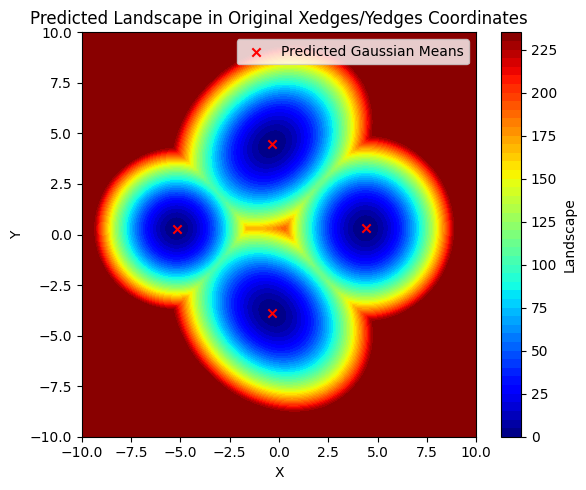

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=5,
    num_components=4,
    hidden_dims=[512, 1024, 512]
)

model.load_state_dict(
    torch.load(
        'best_model_in5_K4_512-1024-512_testloss0.084797.pth',
        map_location='cpu'
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
#input_params = [3.286523104,	2.136327982,	1.122069955,	1.085741997,	0.113086]
input_params = [3.0, 1.9, 0.6, 1.0, 0.3]

# input_params = [3.45, 2.2, 0.15, 0.95, 0.45]
# input_params = [3.15, 1.6, 1.05, 1.05, 0.35]
# input_params = [2.775, 1.65, 0.375, 1.025, 0.475]
# input_params = [3.375, 2.05, 0.975, 0.825, 0.275]

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 得到模型预测输出
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

print("预测的混合权重：")
print(weights.numpy())

print("预测的均值，非负训练坐标系：")
print(means.numpy())

print("预测的协方差矩阵：")
print(covariances.numpy())


# ============================================================
# 4. 转为 numpy
# ============================================================
weights_np = weights[0].cpu().numpy()
means_np = means[0].cpu().numpy()
covariances_np = covariances[0].cpu().numpy()


# ============================================================
# 5. 设置训练时使用的非负坐标范围
# ============================================================
# 这里要和你训练代码中的网格一致
# 如果你的训练数据是 edges=0.05，则 dx = 0.05
dx = 0.05

# 这里设置模型坐标系中的绘图范围
# 例如训练时 max_n = 400，则非负坐标中心大概是 0.025 到 19.975
# 你也可以根据自己的 max_n 修改
x_model_min = 0.0
x_model_max = 20.0
y_model_min = 0.0
y_model_max = 20.0

num_x = 400
num_y = 400

x_model = np.linspace(x_model_min, x_model_max, num_x)
y_model = np.linspace(y_model_min, y_model_max, num_y)

X_model, Y_model = np.meshgrid(x_model, y_model)
pos_model = np.dstack((X_model, Y_model))


# ============================================================
# 6. 在非负模型坐标系中计算 GMM 密度
# ============================================================
Z = np.zeros(X_model.shape)

for i in range(len(weights_np)):
    rv = multivariate_normal(
        mean=means_np[i],
        cov=covariances_np[i],
        allow_singular=True
    )

    Z += weights_np[i] * rv.pdf(pos_model)


# ============================================================
# 7. 把坐标轴平移回真实 Xedges / Yedges 坐标
# ============================================================

X_MIN = -10.0   # <<< 改成你的原始 Xedges 最小值
Y_MIN = -10.0   # <<< 改成你的原始 Yedges 最小值

X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

means_true = means_np.copy()
means_true[:, 0] = means_true[:, 0] + X_MIN
means_true[:, 1] = means_true[:, 1] + Y_MIN

print("预测的均值，平移回原始坐标系后：")
print(means_true)


# ============================================================
# 8. 绘制 landscape
# ============================================================
landscape = -np.log(np.maximum(Z, 1e-100))

plt.figure(figsize=(6, 5))

plt.contourf(
    X_true,
    Y_true,
    landscape,
    levels=50,
    cmap='jet'
)

plt.colorbar(label='Landscape')

plt.scatter(
    means_true[:, 0],
    means_true[:, 1],
    c='red',
    marker='x',
    label='Predicted Gaussian Means'
)

plt.title("Predicted Landscape in Original Xedges/Yedges Coordinates")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.tight_layout()
plt.show()